# Phase-Level (Take-off / Cruise / Landing) RMSE / MAE: Panasonic25 -> CMU eVTOL Transfer

For each of the seven CMU "core seven" target cells, this notebook builds a
framework x flight-phase summary table and grouped bar chart of
`RMSE / MAE (% SOC)`, restricted to each framework's own **Primary adapted**
configuration (the same selection used by notebook 38's "Primary adapted"
column -- reused identically here, never re-derived). This notebook does
**not** modify notebook 37, notebook 38, any runner script, or any Drive
result file; it only reads existing phase-level metric outputs.

> **Preview status.** Every framework's own `run_metadata.json` in this
> repo sets `formal_benchmark_eligible: false`. DTNN's numbers below come
> from its 5-epoch **screening** run (its `formal` run has no per-phase
> metrics file at all -- see the verified-facts note below). Nothing here
> is a final benchmark number.

## What was verified before writing this notebook (not assumed)

1. **Real phase-label vocabulary.** `src/battery_benchmark/datasets/cmu_evtol/ns_phase_labeling_v1.py`
   defines the canonical Ns -> phase mapping used across the whole repo:
   `{0: cc_charge, 1: cv_charge, 3: rest_2, 4: take_off, 5: cruise,
   6: landing, 7: rest_1}`, with `MISSION_FLIGHT_PHASE_ROLES = ("take_off",
   "cruise", "landing")`. `src/battery_benchmark/benchmarks/cmu_diagnostics.py`
   confirms the canonical **prediction-level column name is `mission_phase`**
   (computed the same way), and that flight-phase analysis should focus on
   exactly these three values. `development_pipeline_v0.py`'s own comment
   confirms this **replaced** an older, now-retired power-heuristic naming
   scheme (`"high_1"/"lower"/"high_2"`) -- i.e. the old naming a careless
   notebook might guess is specifically wrong; the current real names are
   `take_off` / `cruise` / `landing`.
2. **Every framework's own `phase_metrics.csv` (downloaded and decoded
   directly, not assumed) uses exactly these three values in its
   `mission_phase` column -- no charge/rest rows are present in any of
   them**, so no phase-filtering step is needed beyond selecting the
   Primary-adapted method/budget row:
   - DTNN screening: `phase_metrics_full_mission_diagnostic.csv` -- columns
     `repeat, seed, cell_id, method, mission_phase, n_points, n_missions,
     mae_percent, rmse_percent, mean_signed_error_percent`; methods
     `Source only, Bian MDA`; 7 cells x 2 methods x 3 phases = 42 rows, all
     present.
   - DARM (`liu_2025_darm_ns_relabel_v2_e30_clean`, the confirmed **v2**
     folder -- a decoy `phase_metrics.csv` also exists inside an older,
     unrelated `..._v1` folder and was explicitly avoided): same column
     schema as DTNN's file plus `condition`; methods `Source only, DARM`;
     7 cells x 2 methods x 3 phases = 42 rows, all present.
   - Backbone (`backbone_transfer_ns_relabel_v2`): columns `model, cell_id,
     condition, budget, mission_phase, n_points, n_missions, mae_percent,
     rmse_percent, mean_signed_error_percent`; 3 models x 6 budgets x 7
     cells x 3 phases = 378 rows; the `full` budget subset used here has
     3 models x 7 cells x 3 phases = 63 rows, all present.
   - SFTNN (`sftnn_med_transfer_ns_relabel_v2`): same schema as DARM's;
     methods `dann_mmd, med, zero_shot`; 7 cells x 3 methods x 3 phases =
     63 rows, all present.
   - Vidal has **no separate `phase_metrics.csv`** (a targeted Drive
     search for `title contains 'phase' and title contains 'vidal'`
     returned empty). Instead its per-setting `cell_metrics.csv` already
     embeds per-phase columns directly: `take_off_mae, take_off_rmse,
     cruise_mae, cruise_rmse, landing_mae, landing_rmse` (fraction scale,
     like its `overall_mae` / `overall_rmse`) -- re-confirmed in this
     window with a fresh download of `vidal_full`'s `cell_metrics.csv`,
     which has all 7 core cells populated for all three phase columns.
   - **TATN**: a targeted search of TATN's own folder tree for any file
     with "phase" in the title returned empty, on top of notebook 38's
     already-established finding that TATN's protocol match with the
     current `ns_relabel_v2` manifest cannot be confirmed at all (no
     `manifest_sha256`, ~5-week-older runs, a different per-cell
     OOD-condition file structure). **TATN is excluded from this notebook
     entirely** -- no row, no bar, no substituted old aggregate, no
     interpolation. This is reported below as a skipped framework, not
     silently dropped.
3. **Primary-adapted selection reuses notebook 38's rule exactly** (same
   `PRIMARY_ADAPTED_SELECTOR` dict, redefined identically here so this
   notebook has no import dependency on notebook 38's file):
   `Vidal Fine-tuning -> vidal_full`, `CNN-LSTM/TCN/Transformer Encoder ->
   full`, `DTNN -> method=="Bian MDA"` (screening), `DARM ->
   method=="DARM"`, `SFTNN (MED) -> method=="med"`, `TATN -> excluded`.
   No budget sweep is read for the phase-level figures -- only each
   framework's own single Primary-adapted row.
4. **`evaluation_unit` is preserved per framework, never resampled.**
   DARM and Vidal report `last_step_per_window`; Backbone, DTNN and SFTNN
   report `all_timesteps` -- consistent with notebook 38's own
   per-framework unit notes. This notebook never interpolates or
   resamples one framework's points to match another's count.
5. **Vidal's embedded phase columns have no separate per-phase point
   count** (its `cell_metrics.csv` only records overall `test_windows`,
   not a per-phase breakdown) -- `n_points` / `n_missions` are left blank
   for Vidal's phase rows rather than fabricated from the overall count.

## Phase order and display names (fixed globally, used identically by all 7 cells)

```
PHASE_ORDER = ["take_off", "cruise", "landing"]
PHASE_DISPLAY_MAP = {"take_off": "Take-off", "cruise": "Cruise", "landing": "Landing"}
```

## Deferred (not in this pass)

Across-cell averaging/mean-median (a possible future step) and a combined
MAE figure (the MAE plotting function is pre-built but only invoked
per-cell, not for a combined figure) are both explicitly out of scope this
pass.

In [1]:
"""Code Cell 1 -- imports, Drive mount, and Drive paths.

Same hardcoded-Drive-path convention as notebooks 37 and 38: no dependency
on a cloned repo checkout inside the Colab runtime, only that Drive is
mounted."""

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

try:
    import google.colab  # noqa: F401

    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
except ImportError:
    pass

DRIVE_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark")
OUTPUT_ROOT = DRIVE_ROOT / "outputs"
BENCH_ROOT = OUTPUT_ROOT / "benchmarks" / "panasonic_to_cmu_evtol"

print("DRIVE_ROOT  :", DRIVE_ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("BENCH_ROOT  :", BENCH_ROOT)


Mounted at /content/drive
DRIVE_ROOT  : /content/drive/MyDrive/battery_soc_benchmark
OUTPUT_ROOT : /content/drive/MyDrive/battery_soc_benchmark/outputs
BENCH_ROOT  : /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol


In [2]:
"""Code Cell 2 -- configuration: cells, phase order, per-framework paths."""

# Same fixed cell order as notebooks 37/38.
CELL_IDS = ["VAH01", "VAH17", "VAH27", "VAH30", "VAH15", "VAH12", "VAH11"]

# Fixed globally, verified against real phase-metric files (see title-cell
# note 1/2) -- never auto-derived per cell.
PHASE_ORDER = ["take_off", "cruise", "landing"]
PHASE_DISPLAY_MAP = {"take_off": "Take-off", "cruise": "Cruise", "landing": "Landing"}

# Frameworks confirmed to have real phase-level metrics (TATN excluded --
# see title-cell note 2).
FRAMEWORK_ROW_ORDER = [
    "Vidal Fine-tuning",
    "CNN-LSTM",
    "TCN",
    "Transformer Encoder",
    "DTNN",
    "DARM",
    "SFTNN (MED)",
]

# Same selection rule as notebook 38's PRIMARY_ADAPTED_SELECTOR, redefined
# identically here (no cross-notebook import dependency).
PRIMARY_ADAPTED_SELECTOR = {
    "Vidal Fine-tuning": ("budget_internal", "vidal_full"),
    "CNN-LSTM": ("budget_internal", "full"),
    "TCN": ("budget_internal", "full"),
    "Transformer Encoder": ("budget_internal", "full"),
    "DTNN": ("method", "Bian MDA"),
    "DARM": ("method", "DARM"),
    "SFTNN (MED)": ("method", "med"),
}

# ---- Vidal: only the vidal_full setting is needed (Primary adapted only). ----
VIDAL_ROOT = BENCH_ROOT / "vidal"
VIDAL_SEED = 42
VIDAL_FULL_RUN_ID = "20260916_192416"
VIDAL_FULL_METRICS = VIDAL_ROOT / "vidal_full" / f"seed_{VIDAL_SEED}" / VIDAL_FULL_RUN_ID / "cell_metrics.csv"

# ---- Backbone: one shared phase_metrics.csv, split by `model`. ----
BACKBONE_DIR = BENCH_ROOT / "backbone_transfer_ns_relabel_v2"
BACKBONE_PHASE_METRICS = BACKBONE_DIR / "phase_metrics.csv"
BACKBONE_MODEL_TO_DISPLAY_NAME = {
    "cnn_lstm": "CNN-LSTM",
    "tcn": "TCN",
    "transformer_encoder": "Transformer Encoder",
}

# ---- DTNN: screening only (formal has no phase_metrics file at all). ----
DTNN_DIR = BENCH_ROOT / "bian_2021" / "initial_soc_70_v2"
DTNN_SCREENING_PHASE_METRICS = DTNN_DIR / "screening" / "phase_metrics_full_mission_diagnostic.csv"

# ---- DARM: confirmed-current v2 folder (NOT the older v1 decoy). ----
DARM_DIR = BENCH_ROOT / "liu_2025_darm_ns_relabel_v2_e30_clean"
DARM_PHASE_METRICS = DARM_DIR / "phase_metrics.csv"

# ---- SFTNN. ----
SFTNN_DIR = BENCH_ROOT / "sftnn_med_transfer_ns_relabel_v2"
SFTNN_PHASE_METRICS = SFTNN_DIR / "phase_metrics.csv"

# ---- TATN: excluded (see title-cell note 2). Kept only for the skip warning. ----
TATN_DIR = OUTPUT_ROOT / "reproductions" / "shen_2023" / "tatn_layout_ablation"

OUTPUT_DIR = Path("phase_metric_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURES_DIR = OUTPUT_DIR  # per-cell PNGs are written directly under OUTPUT_DIR per the requested layout

print("CELL_IDS:", CELL_IDS)
print("PHASE_ORDER:", PHASE_ORDER)
print("PHASE_DISPLAY_MAP:", PHASE_DISPLAY_MAP)
print("FRAMEWORK_ROW_ORDER (TATN excluded):", FRAMEWORK_ROW_ORDER)


CELL_IDS: ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
PHASE_ORDER: ['take_off', 'cruise', 'landing']
PHASE_DISPLAY_MAP: {'take_off': 'Take-off', 'cruise': 'Cruise', 'landing': 'Landing'}
FRAMEWORK_ROW_ORDER (TATN excluded): ['Vidal Fine-tuning', 'CNN-LSTM', 'TCN', 'Transformer Encoder', 'DTNN', 'DARM', 'SFTNN (MED)']


In [3]:
"""Code Cell -- real-Drive path existence diagnostics for every phase-level
metric source this notebook reads, before any loader runs."""

_diagnostic_paths = {
    "VIDAL_FULL_METRICS": VIDAL_FULL_METRICS,
    "BACKBONE_PHASE_METRICS": BACKBONE_PHASE_METRICS,
    "DTNN_SCREENING_PHASE_METRICS": DTNN_SCREENING_PHASE_METRICS,
    "DARM_PHASE_METRICS": DARM_PHASE_METRICS,
    "SFTNN_PHASE_METRICS": SFTNN_PHASE_METRICS,
}

print("=" * 78)
print("PATH EXISTENCE DIAGNOSTICS (real Drive, checked before loading)")
print("=" * 78)
_any_missing = False
for name, p in _diagnostic_paths.items():
    exists = p.exists()
    _any_missing = _any_missing or not exists
    print(f"{name:30s} {str(p.resolve()) if exists else str(p):100s} exists={exists}")
if _any_missing:
    print("\n[WARNING] One or more expected paths are missing on this Drive mount. "
          "The corresponding loader below will emit a skip warning and that framework will "
          "be left out of the affected cell's table/plot rather than guessed.")
else:
    print("\nAll checked paths exist.")


PATH EXISTENCE DIAGNOSTICS (real Drive, checked before loading)
VIDAL_FULL_METRICS             /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal/vidal_full/seed_42/20260916_192416/cell_metrics.csv exists=True
BACKBONE_PHASE_METRICS         /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/backbone_transfer_ns_relabel_v2/phase_metrics.csv exists=True
DTNN_SCREENING_PHASE_METRICS   /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/screening/phase_metrics_full_mission_diagnostic.csv exists=True
DARM_PHASE_METRICS             /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/liu_2025_darm_ns_relabel_v2_e30_clean/phase_metrics.csv exists=True
SFTNN_PHASE_METRICS            /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/sftnn_med_transfer_ns_relabel_v2/phase_metrics.csv exi

In [4]:
"""Code Cell 3 -- metric-unit normalization helper (same heuristic as
notebook 38's ensure_percent_scale)."""


def ensure_percent_scale(series: pd.Series) -> pd.Series:
    if series.empty:
        return series
    s = pd.to_numeric(series, errors="coerce")
    if s.dropna().empty:
        return s
    if s.abs().max() <= 1.5:
        return s * 100.0
    return s


In [5]:
"""Code Cell 4 -- per-framework phase-level metric loaders.

Each loader returns a list of dict records with the common
`phase_metric_long` schema: cell_id, framework, phase_internal,
phase_display, rmse, mae, evaluation_unit, source_file, source_path,
method, model, budget, seed_or_repeat, is_screening,
formal_benchmark_eligible, notes.

Every loader prefers an existing recorded phase-metrics file over
recomputing from predictions; none of these frameworks required falling
back to prediction-level computation (all had a real phase_metrics.csv, or
-- for Vidal -- embedded phase columns in cell_metrics.csv)."""

_skip_warnings = []


def _read_csv_safely(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        return None
    return pd.read_csv(path)


def load_vidal_phase_records() -> list[dict]:
    records = []
    df = _read_csv_safely(VIDAL_FULL_METRICS)
    if df is None:
        _skip_warnings.append("Vidal Fine-tuning: vidal_full cell_metrics.csv not found -- skipped entirely.")
        return records
    for _, row in df.iterrows():
        for phase in PHASE_ORDER:
            rmse_col, mae_col = f"{phase}_rmse", f"{phase}_mae"
            if rmse_col not in row or mae_col not in row:
                continue
            rmse = ensure_percent_scale(pd.Series([row[rmse_col]])).iloc[0]
            mae = ensure_percent_scale(pd.Series([row[mae_col]])).iloc[0]
            records.append(dict(
                cell_id=row["cell_id"], framework="Vidal Fine-tuning",
                phase_internal=phase, phase_display=PHASE_DISPLAY_MAP[phase],
                rmse=rmse, mae=mae, evaluation_unit="last_step_per_window",
                source_file="cell_metrics.csv", source_path=str(VIDAL_FULL_METRICS),
                method="fine_tuned", model=None, budget="vidal_full",
                seed_or_repeat=VIDAL_SEED, is_screening=False, formal_benchmark_eligible=False,
                notes="Per-phase columns embedded directly in Vidal's cell_metrics.csv "
                      "(no separate phase_metrics.csv exists for Vidal); no per-phase "
                      "point count is recorded in this file (only overall test_windows), "
                      "so n_points/n_missions are left blank for Vidal rows rather than fabricated.",
            ))
    return records


def load_backbone_phase_records() -> list[dict]:
    records = []
    df = _read_csv_safely(BACKBONE_PHASE_METRICS)
    if df is None:
        for display in BACKBONE_MODEL_TO_DISPLAY_NAME.values():
            _skip_warnings.append(f"{display}: phase_metrics.csv not found -- skipped entirely.")
        return records
    full_only = df[df["budget"] == "full"]
    for _, row in full_only.iterrows():
        model = row["model"]
        display = BACKBONE_MODEL_TO_DISPLAY_NAME.get(model, model)
        phase = row["mission_phase"]
        if phase not in PHASE_ORDER:
            continue
        records.append(dict(
            cell_id=row["cell_id"], framework=display,
            phase_internal=phase, phase_display=PHASE_DISPLAY_MAP[phase],
            rmse=row.get("rmse_percent", np.nan), mae=row.get("mae_percent", np.nan),
            evaluation_unit="all_timesteps", source_file="phase_metrics.csv",
            source_path=str(BACKBONE_PHASE_METRICS), method="fine_tuned", model=model,
            budget="full", seed_or_repeat=None,
            n_points=row.get("n_points", np.nan), n_missions=row.get("n_missions", np.nan),
            is_screening=False, formal_benchmark_eligible=False, notes="",
        ))
    return records


def load_dtnn_phase_records() -> list[dict]:
    records = []
    df = _read_csv_safely(DTNN_SCREENING_PHASE_METRICS)
    if df is None:
        _skip_warnings.append("DTNN: screening phase_metrics_full_mission_diagnostic.csv not found -- skipped entirely.")
        return records
    mda_only = df[df["method"] == "Bian MDA"]
    for _, row in mda_only.iterrows():
        phase = row["mission_phase"]
        if phase not in PHASE_ORDER:
            continue
        records.append(dict(
            cell_id=row["cell_id"], framework="DTNN",
            phase_internal=phase, phase_display=PHASE_DISPLAY_MAP[phase],
            rmse=row.get("rmse_percent", np.nan), mae=row.get("mae_percent", np.nan),
            evaluation_unit="all_timesteps", source_file="phase_metrics_full_mission_diagnostic.csv",
            source_path=str(DTNN_SCREENING_PHASE_METRICS), method="Bian MDA", model=None,
            budget=None, seed_or_repeat=row.get("repeat", row.get("seed")),
            n_points=row.get("n_points", np.nan), n_missions=row.get("n_missions", np.nan),
            is_screening=True, formal_benchmark_eligible=False,
            notes="DTNN 5-epoch screening run; the formal run (5 repeats) has no "
                  "phase_metrics file at all, so it cannot be used even as a fallback.",
        ))
    return records


def load_darm_phase_records() -> list[dict]:
    records = []
    df = _read_csv_safely(DARM_PHASE_METRICS)
    if df is None:
        _skip_warnings.append("DARM: phase_metrics.csv not found -- skipped entirely.")
        return records
    darm_only = df[df["method"] == "DARM"]
    for _, row in darm_only.iterrows():
        phase = row["mission_phase"]
        if phase not in PHASE_ORDER:
            continue
        records.append(dict(
            cell_id=row["cell_id"], framework="DARM",
            phase_internal=phase, phase_display=PHASE_DISPLAY_MAP[phase],
            rmse=row.get("rmse_percent", np.nan), mae=row.get("mae_percent", np.nan),
            evaluation_unit="last_step_per_window", source_file="phase_metrics.csv",
            source_path=str(DARM_PHASE_METRICS), method="DARM", model=None,
            budget=None, seed_or_repeat=None,
            n_points=row.get("n_points", np.nan), n_missions=row.get("n_missions", np.nan),
            is_screening=False, formal_benchmark_eligible=False,
            notes=f"condition={row.get('condition')!r} (DARM's per-cell OOD test condition, "
                  "not a budget tier).",
        ))
    return records


def load_sftnn_phase_records() -> list[dict]:
    records = []
    df = _read_csv_safely(SFTNN_PHASE_METRICS)
    if df is None:
        _skip_warnings.append("SFTNN (MED): phase_metrics.csv not found -- skipped entirely.")
        return records
    med_only = df[df["method"] == "med"]
    for _, row in med_only.iterrows():
        phase = row["mission_phase"]
        if phase not in PHASE_ORDER:
            continue
        records.append(dict(
            cell_id=row["cell_id"], framework="SFTNN (MED)",
            phase_internal=phase, phase_display=PHASE_DISPLAY_MAP[phase],
            rmse=row.get("rmse_percent", np.nan), mae=row.get("mae_percent", np.nan),
            evaluation_unit="all_timesteps", source_file="phase_metrics.csv",
            source_path=str(SFTNN_PHASE_METRICS), method="med", model=None,
            budget=None, seed_or_repeat=None,
            n_points=row.get("n_points", np.nan), n_missions=row.get("n_missions", np.nan),
            is_screening=False, formal_benchmark_eligible=False,
            notes="SFTNN MED uses no target labels at all during transfer (pseudo-labels only).",
        ))
    return records


def check_tatn_phase_availability() -> None:
    """TATN is excluded per title-cell note 2: no phase_metrics file exists
    in its folder tree, and notebook 38 already established its protocol
    match with the current benchmark cannot be confirmed. This function
    only records the skip -- it never substitutes an old aggregate."""
    _skip_warnings.append(
        "TATN: excluded entirely -- no phase-level metric file was found in its folder tree, "
        "and its protocol match with the current ns_relabel_v2 manifest could not be confirmed "
        "(see notebook 38's title-cell note 7). No row, no bar, no substituted aggregate."
    )


In [6]:
"""Code Cell 5 -- build the long-form master table `phase_metric_long`."""

_all_phase_records = []
_all_phase_records += load_vidal_phase_records()
_all_phase_records += load_backbone_phase_records()
_all_phase_records += load_dtnn_phase_records()
_all_phase_records += load_darm_phase_records()
_all_phase_records += load_sftnn_phase_records()
check_tatn_phase_availability()

phase_metric_long = pd.DataFrame.from_records(_all_phase_records)

_expected_cols = [
    "cell_id", "framework", "phase_internal", "phase_display", "rmse", "mae",
    "evaluation_unit", "source_file", "source_path", "method", "model", "budget",
    "seed_or_repeat", "n_points", "n_missions", "is_screening",
    "formal_benchmark_eligible", "notes",
]
phase_metric_long = phase_metric_long.reindex(columns=_expected_cols)
phase_metric_long["phase_internal"] = pd.Categorical(
    phase_metric_long["phase_internal"], categories=PHASE_ORDER, ordered=True
)

_n_fw = phase_metric_long["framework"].nunique()
print(f"phase_metric_long: {len(phase_metric_long)} rows, {_n_fw} frameworks")
print(phase_metric_long["framework"].value_counts())
print("\nSkip warnings:")
for w in _skip_warnings:
    print("  [SKIP]", w)
phase_metric_long.head(10)


phase_metric_long: 147 rows, 7 frameworks
framework
Vidal Fine-tuning      21
CNN-LSTM               21
TCN                    21
Transformer Encoder    21
DTNN                   21
DARM                   21
SFTNN (MED)            21
Name: count, dtype: int64

Skip warnings:
  [SKIP] TATN: excluded entirely -- no phase-level metric file was found in its folder tree, and its protocol match with the current ns_relabel_v2 manifest could not be confirmed (see notebook 38's title-cell note 7). No row, no bar, no substituted aggregate.


,cell_id,framework,phase_internal,phase_display,rmse,mae,evaluation_unit,source_file,source_path,method,model,budget,seed_or_repeat,n_points,n_missions,is_screening,formal_benchmark_eligible,notes
0,VAH01,Vidal Fine-tuning,take_off,Take-off,2.204055,2.110428,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
1,VAH01,Vidal Fine-tuning,cruise,Cruise,2.343355,2.068735,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
2,VAH01,Vidal Fine-tuning,landing,Landing,0.746592,0.633416,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
3,VAH17,Vidal Fine-tuning,take_off,Take-off,0.274957,0.219458,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
4,VAH17,Vidal Fine-tuning,cruise,Cruise,1.538174,0.997825,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
5,VAH17,Vidal Fine-tuning,landing,Landing,2.418147,1.896641,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
6,VAH27,Vidal Fine-tuning,take_off,Take-off,6.693274,6.487452,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
7,VAH27,Vidal Fine-tuning,cruise,Cruise,2.622859,2.129774,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
8,VAH27,Vidal Fine-tuning,landing,Landing,2.369771,1.917934,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...
9,VAH30,Vidal Fine-tuning,take_off,Take-off,1.014100,0.987777,last_step_per_window,cell_metrics.csv,/content/drive/MyDrive/battery_soc_benchmark/o...,fine_tuned,None,vidal_full,42.0,NaN,NaN,False,False,Per-phase columns embedded directly in Vidal's...


In [7]:
"""Code Cell 6 -- pre-plot diagnostics: print every (cell, framework, phase)
combination with its point/mission count, metric values, evaluation_unit
and source; flag zero-point combos, DARM/Vidal sparse coverage, and
phase-label consistency across frameworks."""

print("=" * 100)
print("PHASE-LEVEL DIAGNOSTIC DUMP")
print("=" * 100)
_diag_cols = ["cell_id", "framework", "phase_internal", "n_points", "n_missions",
              "rmse", "mae", "evaluation_unit", "source_file"]
print(phase_metric_long[_diag_cols].sort_values(["framework", "cell_id", "phase_internal"]).to_string(index=False))

print("\n--- Checks ---")
_diag_warnings = []

# Zero-point framework/phase combinations.
_zero_points = phase_metric_long[(phase_metric_long["n_points"] == 0) | (phase_metric_long["n_missions"] == 0)]
if len(_zero_points):
    _diag_warnings.append(f"{len(_zero_points)} rows have n_points==0 or n_missions==0")

# DARM / Vidal sparse-evaluation phase coverage: each should have exactly
# 3 phases per cell (no partial phase coverage).
for framework in ["DARM", "Vidal Fine-tuning"]:
    sub = phase_metric_long[phase_metric_long["framework"] == framework]
    counts = sub.groupby("cell_id", observed=True)["phase_internal"].nunique()
    incomplete = counts[counts < len(PHASE_ORDER)]
    if len(incomplete):
        _diag_warnings.append(f"{framework} has incomplete phase coverage for cells: {list(incomplete.index)}")

# Phase-label consistency: every framework present should only use the
# fixed PHASE_ORDER values (enforced by construction via the phase in
# PHASE_ORDER filter in each loader, but re-checked here defensively).
_bad_phases = set(phase_metric_long["phase_internal"].dropna().astype(str)) - set(PHASE_ORDER)
if _bad_phases:
    _diag_warnings.append(f"Unexpected phase_internal values outside PHASE_ORDER: {_bad_phases}")

# Every framework/cell should have all 3 phases (no silent partial rows).
_coverage = phase_metric_long.groupby(["framework", "cell_id"], observed=True)["phase_internal"].nunique()
_partial = _coverage[_coverage < len(PHASE_ORDER)]
if len(_partial):
    _diag_warnings.append(f"{len(_partial)} (framework, cell) combinations have <3 phases:\n{_partial}")

print(f"\n{len(_diag_warnings)} warning(s).")
for w in _diag_warnings:
    print("  [WARNING]", w)
if not _diag_warnings:
    print("  No issues found.")


PHASE-LEVEL DIAGNOSTIC DUMP
cell_id           framework phase_internal  n_points  n_missions      rmse       mae      evaluation_unit                               source_file
  VAH01            CNN-LSTM       take_off   12570.0       170.0  8.235749  5.211074        all_timesteps                         phase_metrics.csv
  VAH01            CNN-LSTM         cruise  161600.0       170.0  1.930723  1.656088        all_timesteps                         phase_metrics.csv
  VAH01            CNN-LSTM        landing   12480.0       170.0  1.303907  0.944758        all_timesteps                         phase_metrics.csv
  VAH11            CNN-LSTM       take_off   33345.0       450.0 10.459689  5.781287        all_timesteps                         phase_metrics.csv
  VAH11            CNN-LSTM         cruise  417600.0       450.0  5.348087  4.717233        all_timesteps                         phase_metrics.csv
  VAH11            CNN-LSTM        landing   33205.0       450.0  8.787768  7.164821

In [8]:
"""Code Cell 7 -- per-cell phase table builder and CSV export helper."""

from IPython.display import display


def _format_cell(rmse, mae) -> str:
    if pd.isna(rmse) or pd.isna(mae):
        return "\u2014"
    return f"{rmse:.2f} / {mae:.2f}"


def build_cell_phase_table(cell_id: str) -> pd.DataFrame:
    """Framework x phase RMSE/MAE table for one battery cell, reading only
    from the already-built `phase_metric_long` (never re-reading Drive per
    table)."""
    sub = phase_metric_long[phase_metric_long["cell_id"] == cell_id]

    rows = []
    for framework in FRAMEWORK_ROW_ORDER:
        fsub = sub[sub["framework"] == framework]
        row = {"Framework": framework}
        for phase in PHASE_ORDER:
            match = fsub[fsub["phase_internal"] == phase]
            col_name = PHASE_DISPLAY_MAP[phase]
            if len(match) == 0:
                row[col_name] = "\u2014"
            elif match["rmse"].nunique() > 1 or match["mae"].nunique() > 1:
                row[col_name] = "\u2014 (conflict)"
            else:
                row[col_name] = _format_cell(match["rmse"].iloc[0], match["mae"].iloc[0])
        rows.append(row)

    columns = ["Framework"] + [PHASE_DISPLAY_MAP[p] for p in PHASE_ORDER]
    return pd.DataFrame(rows, columns=columns)


def display_cell_phase_table(cell_id: str, table: pd.DataFrame) -> None:
    styler = (
        table.style
        .hide(axis="index")
        .set_properties(subset=["Framework"], **{"text-align": "left"})
        .set_properties(subset=[PHASE_DISPLAY_MAP[p] for p in PHASE_ORDER], **{"text-align": "center"})
        .set_caption(f"{cell_id} -- Phase-level RMSE / MAE (% SOC), Primary adapted only")
    )
    display(styler)
    print("Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). "
          "DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded "
          "(no verified phase-level result). See title-cell notes for full detail.")
    table.to_csv(OUTPUT_DIR / f"{cell_id}_phase_metrics.csv", index=False)


In [9]:
"""Code Cell 8 -- shared framework colors and per-cell / combined plotting
functions. Matplotlib only (no seaborn); academic, clean, publication-ready
styling; missing values are always gaps, never zero-filled or reflowed."""

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# Same 7-framework color mapping as notebook 38 (TATN never had a color
# there either, since it was always em-dash in the Primary-adapted column).
FRAMEWORK_COLORS = {
    "Vidal Fine-tuning":   "#2a78d6",  # blue
    "CNN-LSTM":            "#eb6834",  # orange
    "TCN":                 "#1baf7a",  # aqua
    "Transformer Encoder": "#eda100",  # yellow
    "DTNN":                "#e87ba4",  # magenta
    "DARM":                "#008300",  # green
    "SFTNN (MED)":         "#4a3aa7",  # violet
}

ANNOTATE_BARS = False  # 7 frameworks x 3 phases = 21 bars per subplot; off by default

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "font.size": 10,
})


def _framework_label(framework: str) -> str:
    return "DTNN (screening)" if framework == "DTNN" else framework


def _draw_phase_bars(ax, cell_id: str, metric_col: str):
    """Draw one cell's grouped bar chart (phases on x, frameworks as bars
    within each phase group) onto an existing Axes. Shared by both the
    single-cell and combined-figure paths so their bar geometry can never
    drift apart."""
    sub_cell = phase_metric_long[phase_metric_long["cell_id"] == cell_id]
    n_frameworks = len(FRAMEWORK_ROW_ORDER)
    n_phases = len(PHASE_ORDER)
    group_width = 0.82
    bar_width = group_width / n_frameworks

    for fi, framework in enumerate(FRAMEWORK_ROW_ORDER):
        fsub = sub_cell[sub_cell["framework"] == framework].set_index("phase_internal")
        xs, heights = [], []
        for pi, phase in enumerate(PHASE_ORDER):
            if phase not in fsub.index:
                continue
            value = fsub.loc[phase, metric_col]
            if pd.isna(value):
                continue
            x = pi - group_width / 2 + (fi + 0.5) * bar_width
            xs.append(x)
            heights.append(value)
        bars = ax.bar(
            xs, heights, width=bar_width * 0.92, color=FRAMEWORK_COLORS[framework],
            edgecolor="white", linewidth=0.6, label=_framework_label(framework), zorder=3,
        )
        if ANNOTATE_BARS:
            for b in bars:
                ax.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                            xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=7)

    ax.set_xticks(range(n_phases))
    ax.set_xticklabels([PHASE_DISPLAY_MAP[p] for p in PHASE_ORDER])
    ax.set_ylim(bottom=0)
    ax.grid(True, axis="y", alpha=0.25, linewidth=0.6, zorder=0)


def plot_single_cell_phase_metric(cell_id: str, metric: str = "rmse"):
    """Single-cell grouped bar chart: x=phases (PHASE_ORDER), bars=frameworks
    (FRAMEWORK_ROW_ORDER), short cell_id-only title, its own external/top
    legend."""
    metric_col = "rmse" if metric == "rmse" else "mae"
    y_label = "RMSE (% SOC)" if metric == "rmse" else "MAE (% SOC)"

    fig, ax = plt.subplots(figsize=(7, 5.2))
    _draw_phase_bars(ax, cell_id, metric_col)
    ax.set_ylabel(y_label)
    ax.set_xlabel("Flight phase")
    ax.set_title(cell_id, fontsize=12, pad=54)

    handles = [Patch(facecolor=FRAMEWORK_COLORS[f], edgecolor="white", label=_framework_label(f))
               for f in FRAMEWORK_ROW_ORDER]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=8)

    fig.tight_layout()
    out_stem = OUTPUT_DIR / f"{cell_id}_phase_{metric}"
    fig.savefig(out_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    if metric == "rmse":
        # Only RMSE PNGs are part of the requested per-cell PNG set this pass.
        pass
    return fig, ax


def plot_combined_phase_rmse_2x2x2x1():
    """Combined RMSE figure across all 7 cells, laid out 2+2+2+1 via
    GridSpec: 4 rows x 4 cols, each of the first 6 subplots spans 2 cols,
    and the 7th (VAH11) sits centered at gs[3, 1:3] -- same width as the
    paired subplots above it, never full-width. One shared legend only."""
    fig = plt.figure(figsize=(14, 15))
    gs = GridSpec(4, 4, figure=fig, top=0.90, bottom=0.08, hspace=0.55, wspace=0.35)

    slot_specs = [
        (0, slice(0, 2)), (0, slice(2, 4)),
        (1, slice(0, 2)), (1, slice(2, 4)),
        (2, slice(0, 2)), (2, slice(2, 4)),
        (3, slice(1, 3)),  # VAH11: centered, same width as the pairs above
    ]

    for cell_id, (row, col_slice) in zip(CELL_IDS, slot_specs):
        ax = fig.add_subplot(gs[row, col_slice])
        _draw_phase_bars(ax, cell_id, "rmse")
        ax.set_title(cell_id, fontsize=11)
        ax.set_xlabel("Flight phase")
        ax.set_ylabel("RMSE (% SOC)")

    handles = [Patch(facecolor=FRAMEWORK_COLORS[f], edgecolor="white", label=_framework_label(f))
               for f in FRAMEWORK_ROW_ORDER]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.985), ncol=4, frameon=False, fontsize=10)

    fig.suptitle("Phase-level RMSE by framework and target cell (Primary adapted only)", y=1.0, fontsize=13)
    fig.text(0.5, 0.01,
              "Note: DTNN values are based on the current 5-epoch screening run.",
              ha="center", va="top", fontsize=9, style="italic", color="0.35")

    fig.savefig(OUTPUT_DIR / "phase_rmse_all_cells_2x2x2x1.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / "phase_rmse_all_cells_2x2x2x1.pdf", bbox_inches="tight")
    return fig


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,2.20 / 2.11,2.34 / 2.07,0.75 / 0.63
CNN-LSTM,8.24 / 5.21,1.93 / 1.66,1.30 / 0.94
TCN,15.83 / 12.68,2.52 / 2.35,1.35 / 1.03
Transformer Encoder,8.49 / 6.72,2.25 / 2.08,2.03 / 1.73
DTNN,22.58 / 22.14,6.93 / 5.34,9.54 / 8.20
DARM,72.54 / 72.15,46.78 / 43.83,32.56 / 32.42
SFTNN (MED),15.36 / 14.93,10.63 / 8.95,8.41 / 7.82


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


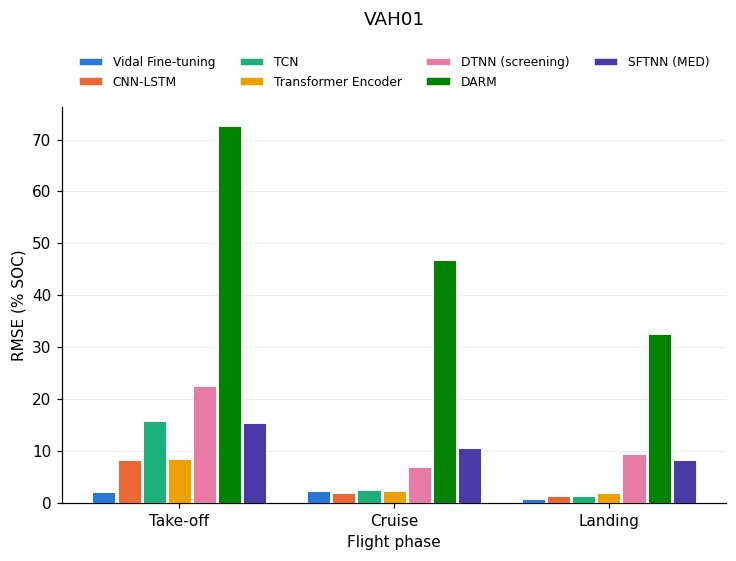

In [10]:
"""Code Cell -- VAH01 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah01 = build_cell_phase_table("VAH01")
display_cell_phase_table("VAH01", table_vah01)
fig_vah01, ax_vah01 = plot_single_cell_phase_metric("VAH01", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,0.27 / 0.22,1.54 / 1.00,2.42 / 1.90
CNN-LSTM,11.33 / 7.39,1.84 / 1.31,3.19 / 1.90
TCN,13.31 / 10.54,1.78 / 1.42,1.42 / 0.95
Transformer Encoder,8.62 / 6.78,1.36 / 1.03,1.17 / 0.89
DTNN,20.16 / 19.77,7.77 / 5.97,8.33 / 7.20
DARM,68.29 / 67.78,43.73 / 40.68,30.80 / 30.64
SFTNN (MED),10.60 / 9.85,12.43 / 11.42,4.18 / 3.21


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


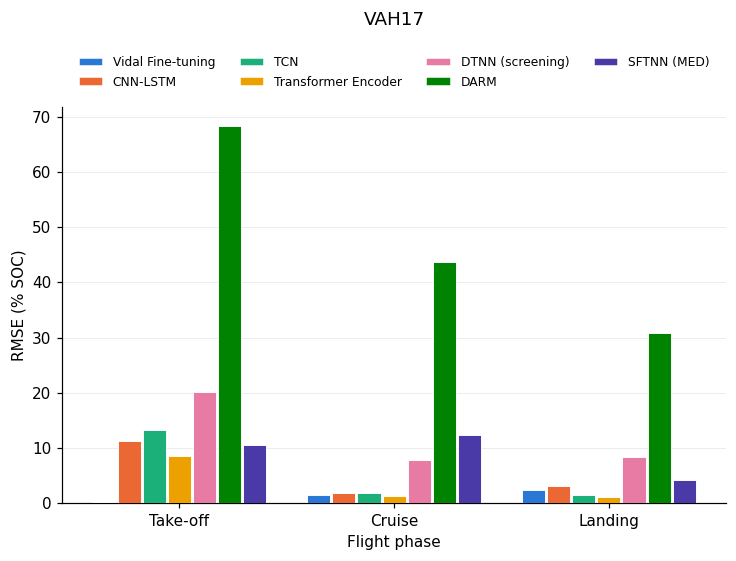

In [11]:
"""Code Cell -- VAH17 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah17 = build_cell_phase_table("VAH17")
display_cell_phase_table("VAH17", table_vah17)
fig_vah17, ax_vah17 = plot_single_cell_phase_metric("VAH17", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,6.69 / 6.49,2.62 / 2.13,2.37 / 1.92
CNN-LSTM,10.11 / 6.66,2.50 / 2.05,5.85 / 3.89
TCN,9.05 / 6.85,2.13 / 1.69,2.15 / 1.52
Transformer Encoder,7.71 / 5.99,1.97 / 1.68,1.16 / 0.91
DTNN,21.52 / 21.19,6.66 / 5.00,10.55 / 9.52
DARM,53.82 / 53.54,24.85 / 22.51,29.64 / 29.01
SFTNN (MED),10.00 / 9.50,9.30 / 8.07,3.62 / 2.86


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


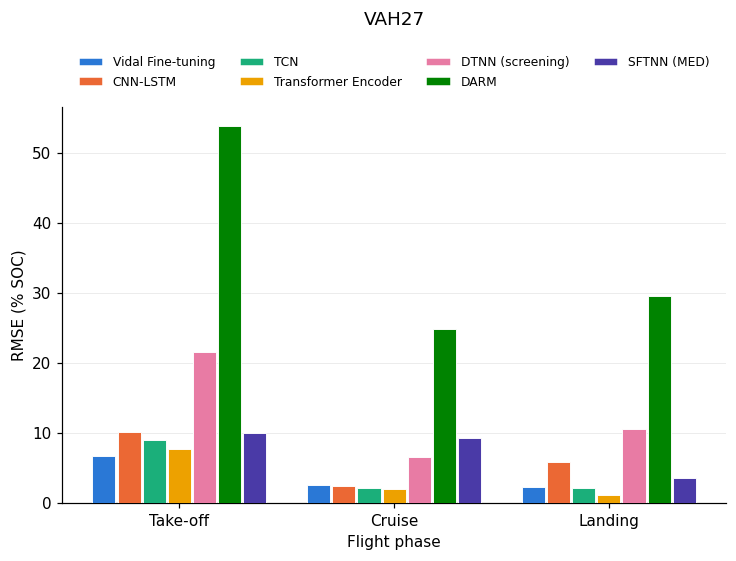

In [12]:
"""Code Cell -- VAH27 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah27 = build_cell_phase_table("VAH27")
display_cell_phase_table("VAH27", table_vah27)
fig_vah27, ax_vah27 = plot_single_cell_phase_metric("VAH27", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,1.01 / 0.99,1.67 / 1.26,1.07 / 0.97
CNN-LSTM,15.36 / 12.65,2.14 / 1.42,1.51 / 1.31
TCN,18.86 / 15.83,1.51 / 1.15,0.76 / 0.62
Transformer Encoder,11.01 / 9.48,2.10 / 1.95,1.10 / 0.98
DTNN,22.49 / 22.19,7.50 / 5.87,6.43 / 5.43
DARM,76.11 / 76.10,41.24 / 39.99,31.53 / 31.27
SFTNN (MED),25.70 / 25.52,12.27 / 11.30,8.44 / 8.31


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


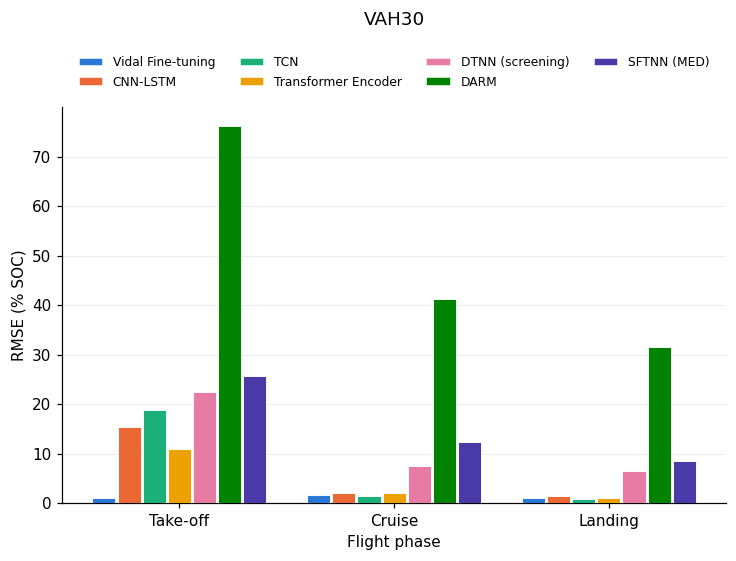

In [13]:
"""Code Cell -- VAH30 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah30 = build_cell_phase_table("VAH30")
display_cell_phase_table("VAH30", table_vah30)
fig_vah30, ax_vah30 = plot_single_cell_phase_metric("VAH30", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,0.25 / 0.21,1.27 / 0.90,1.26 / 1.16
CNN-LSTM,4.33 / 2.86,1.00 / 0.76,1.08 / 0.92
TCN,3.16 / 2.67,1.22 / 1.01,0.59 / 0.44
Transformer Encoder,3.99 / 3.08,0.61 / 0.50,0.95 / 0.76
DTNN,21.01 / 20.72,8.44 / 6.30,5.88 / 5.04
DARM,47.91 / 47.87,19.40 / 15.56,20.80 / 20.59
SFTNN (MED),6.74 / 6.53,9.77 / 9.04,10.19 / 9.76


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


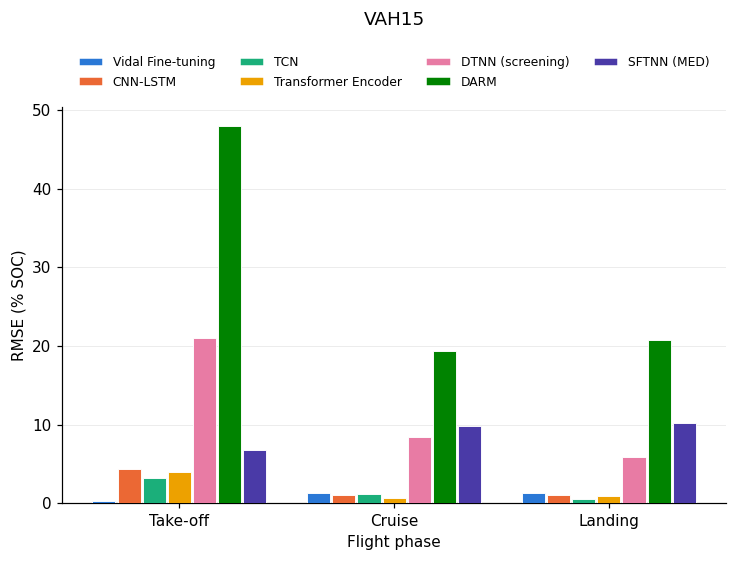

In [14]:
"""Code Cell -- VAH15 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah15 = build_cell_phase_table("VAH15")
display_cell_phase_table("VAH15", table_vah15)
fig_vah15, ax_vah15 = plot_single_cell_phase_metric("VAH15", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,0.49 / 0.40,1.96 / 1.71,7.41 / 7.04
CNN-LSTM,6.18 / 3.44,2.61 / 1.89,2.09 / 1.64
TCN,9.13 / 6.13,4.46 / 3.09,1.94 / 1.54
Transformer Encoder,1.48 / 1.06,1.41 / 1.05,2.05 / 1.54
DTNN,24.06 / 22.14,7.70 / 7.11,16.37 / 15.56
DARM,84.09 / 83.95,47.89 / 44.87,39.16 / 38.81
SFTNN (MED),27.84 / 27.30,9.75 / 6.70,20.19 / 19.30


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


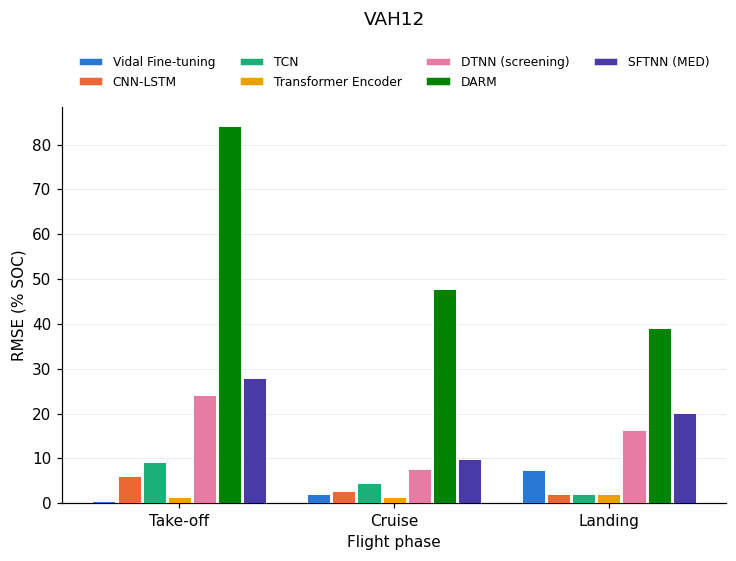

In [15]:
"""Code Cell -- VAH12 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah12 = build_cell_phase_table("VAH12")
display_cell_phase_table("VAH12", table_vah12)
fig_vah12, ax_vah12 = plot_single_cell_phase_metric("VAH12", metric="rmse")
plt.show()


Framework,Take-off,Cruise,Landing
Vidal Fine-tuning,9.05 / 7.03,7.00 / 5.94,12.36 / 6.84
CNN-LSTM,10.46 / 5.78,5.35 / 4.72,8.79 / 7.16
TCN,17.70 / 12.00,5.47 / 4.83,3.98 / 3.22
Transformer Encoder,5.18 / 4.18,5.05 / 4.33,1.46 / 1.17
DTNN,27.07 / 25.09,7.14 / 5.35,16.75 / 15.97
DARM,77.13 / 77.09,19.83 / 17.02,31.03 / 29.17
SFTNN (MED),13.42 / 13.21,6.91 / 3.94,11.04 / 10.17


Preview benchmark outputs; DTNN uses a 5-epoch screening run (preview). DARM and SFTNN(MED) use no target labels at all during adaptation. TATN excluded (no verified phase-level result). See title-cell notes for full detail.


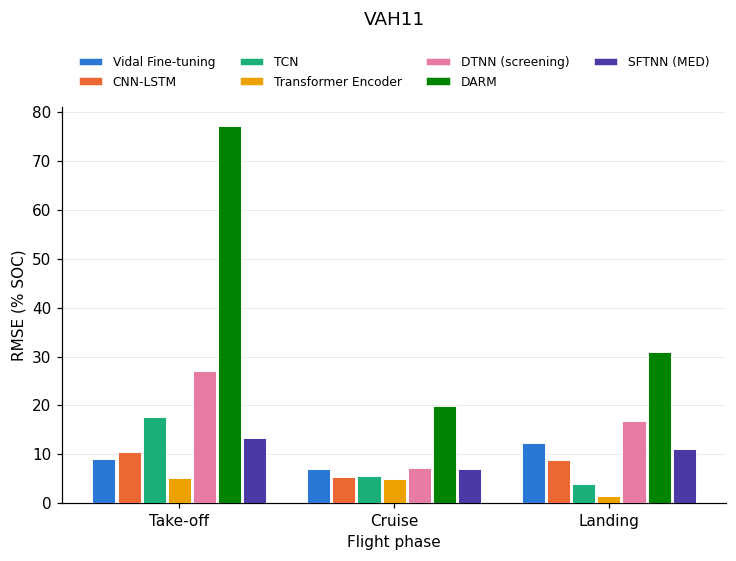

In [16]:
"""Code Cell -- VAH11 phase-level table and RMSE figure (independent
cell, per instruction: one code cell per battery cell, no shared for-loop)."""

table_vah11 = build_cell_phase_table("VAH11")
display_cell_phase_table("VAH11", table_vah11)
fig_vah11, ax_vah11 = plot_single_cell_phase_metric("VAH11", metric="rmse")
plt.show()


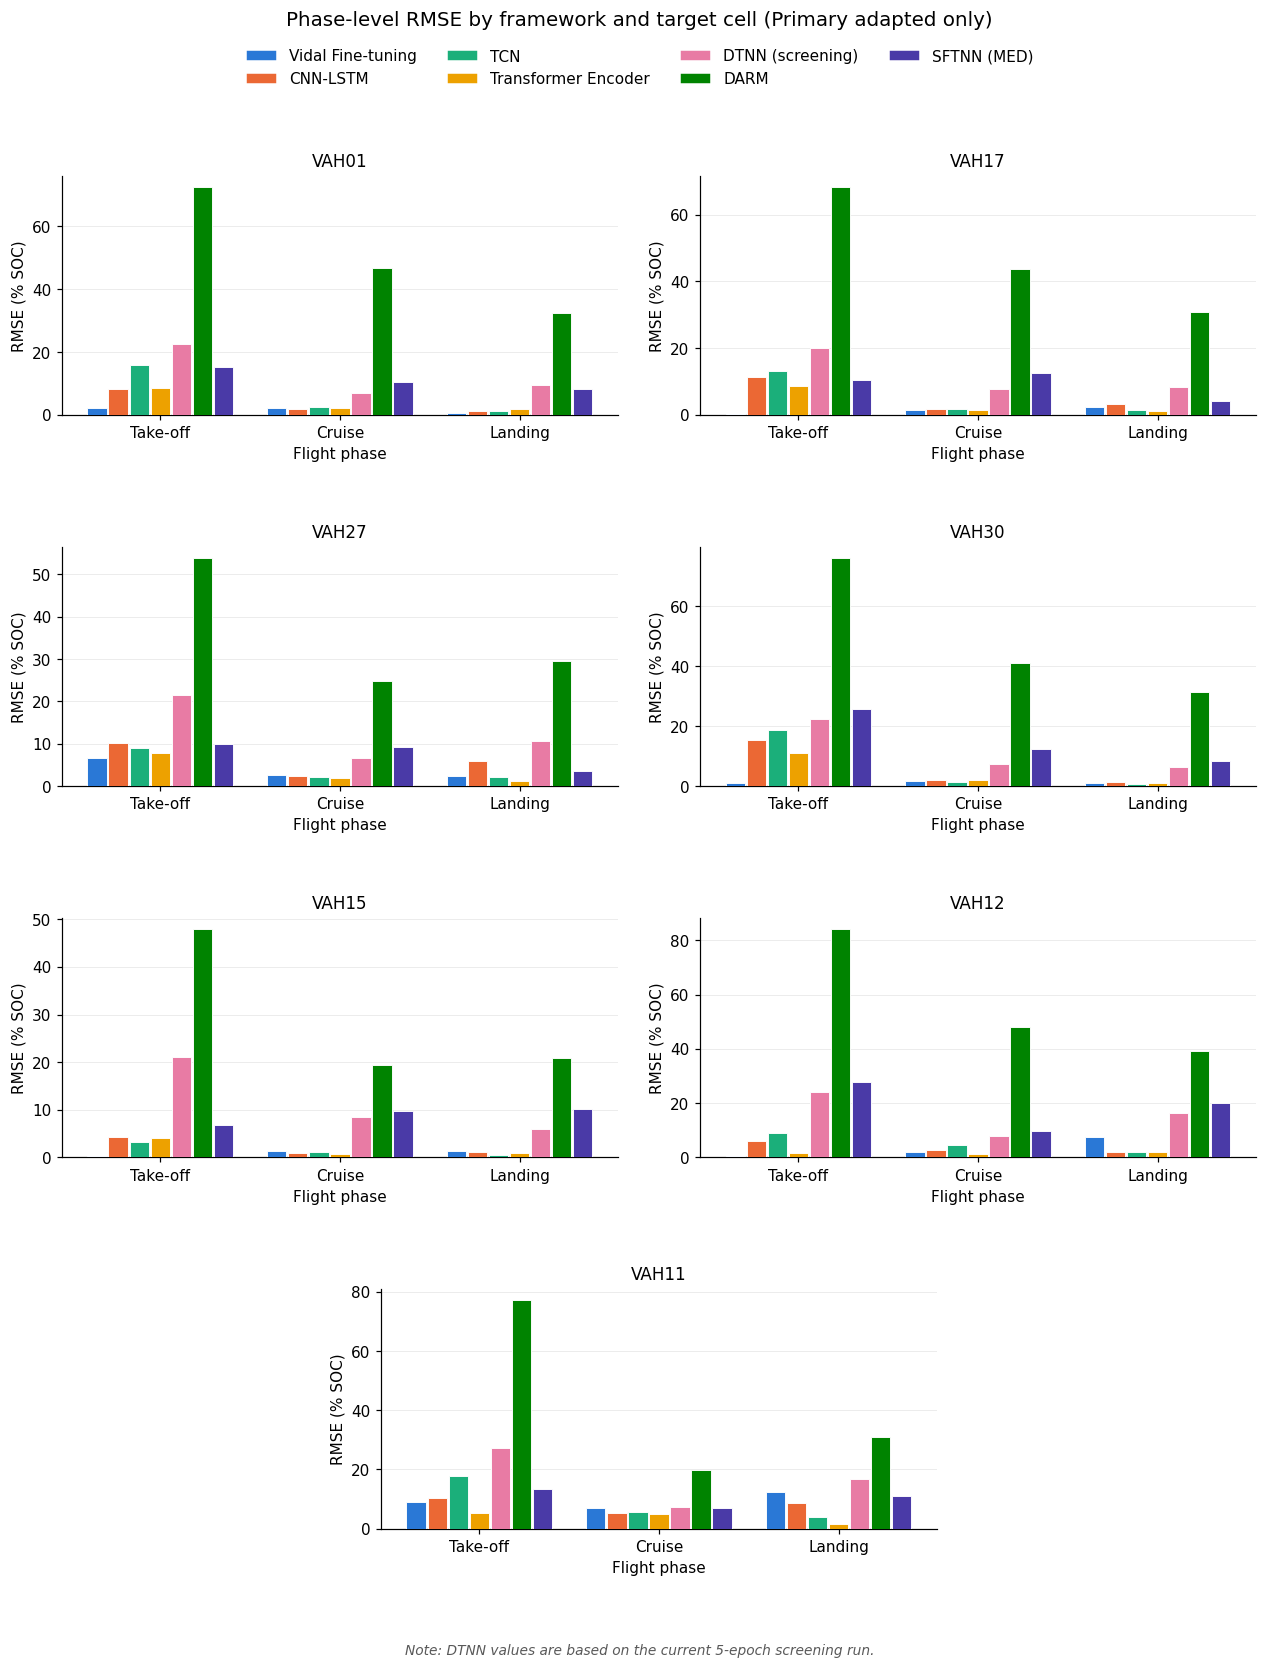

In [17]:
"""Code Cell -- combined 2+2+2+1 phase-level RMSE figure across all 7 cells."""

fig_combined = plot_combined_phase_rmse_2x2x2x1()
plt.show()


In [18]:
"""Code Cell -- combined machine-readable export."""

phase_metric_long.to_csv(OUTPUT_DIR / "all_phase_metrics_long.csv", index=False)
_all_phase_csv_path = OUTPUT_DIR / "all_phase_metrics_long.csv"
print(f"Wrote {_all_phase_csv_path} ({len(phase_metric_long)} rows)")
print(f"\nFiles written to {OUTPUT_DIR}/:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(" ", p.name)


Wrote phase_metric_outputs/all_phase_metrics_long.csv (147 rows)

Files written to phase_metric_outputs/:
  VAH01_phase_metrics.csv
  VAH01_phase_rmse.png
  VAH11_phase_metrics.csv
  VAH11_phase_rmse.png
  VAH12_phase_metrics.csv
  VAH12_phase_rmse.png
  VAH15_phase_metrics.csv
  VAH15_phase_rmse.png
  VAH17_phase_metrics.csv
  VAH17_phase_rmse.png
  VAH27_phase_metrics.csv
  VAH27_phase_rmse.png
  VAH30_phase_metrics.csv
  VAH30_phase_rmse.png
  all_phase_metrics_long.csv
  phase_rmse_all_cells_2x2x2x1.pdf
  phase_rmse_all_cells_2x2x2x1.png


## Deferred (not in this pass)

Across-cell averaging / mean-median summaries (a possible future step) and
a combined MAE figure (the `metric="mae"` path of
`plot_single_cell_phase_metric` is pre-built but only invoked per-cell,
never assembled into a combined GridSpec figure) are both out of scope
this pass.